In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
df_path = "/content/drive/MyDrive/Model/Data sebelum imputasi/Data konsentrasi per jam DKI2-Kelapa Gading.xlsx"
df = pd.read_excel(df_path)
df = df.replace('---', np.nan)
pollutant_cols = ['PM10', 'PM2.5', 'SO2', 'CO', 'O3', 'NO', 'NO2', 'NOX']
df[pollutant_cols] = df[pollutant_cols].replace(0, np.nan)
df.head(10)

/tmp/ipykernel_1437/593703133.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('---', np.nan)


,datetime,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
0,2020-01-01 00:00:00,41.36,15.24,10.79,0.49,65.69,2.27,11.92,7.49,25.940001,1.93,24.400000,91.239998,2.326,0.000000
1,2020-01-01 01:00:00,40.13,16.33,10.43,0.32,59.90,2.11,7.95,5.45,26.090000,1.42,24.370001,90.269997,3.223,0.000000
2,2020-01-01 02:00:00,38.24,7.32,10.25,0.24,58.21,1.21,5.28,3.47,26.590000,0.83,23.980000,85.620003,4.329,0.000000
3,2020-01-01 03:00:00,36.24,7.69,11.00,0.26,65.44,1.17,4.28,2.96,26.830000,0.67,24.150000,85.279999,4.737,0.000000
4,2020-01-01 04:00:00,32.48,7.60,10.83,0.25,71.62,4.51,9.43,7.96,26.709999,0.94,24.340000,86.870003,4.895,0.000000
5,2020-01-01 05:00:00,29.38,17.54,10.97,0.03,57.06,1.23,5.90,3.79,27.000000,1.63,24.379999,85.610001,4.988,0.000000
6,2020-01-01 06:00:00,22.84,6.68,10.22,0.25,35.10,1.34,8.03,4.91,26.940001,2.16,24.389999,85.959999,4.150,25.500000
7,2020-01-01 07:00:00,18.48,5.09,10.25,0.36,60.06,1.98,10.14,6.41,26.770000,1.12,24.480000,87.290001,3.557,88.370003
8,2020-01-01 08:00:00,18.00,5.47,10.18,0.28,52.22,1.38,7.00,4.44,26.950001,1.47,24.309999,85.500000,3.233,152.309998
9,2020-01-01 09:00:00,15.38,7.75,10.25,0.50,42.93,3.58,11.83,8.43,26.990000,1.09,24.280001,85.139999,2.826,182.240005


In [3]:
df.isnull().sum()

,0
datetime,0
PM10,967
PM2.5,908
SO2,1560
CO,1217
O3,1068
NO,1346
NO2,1460
NOX,1120
Suhu Udara (°C),0


In [4]:
missing_percent = df.isnull().mean() * 100
missing_percent_str = missing_percent.round(2).astype(str) + ' %'
(missing_percent.round(2)).astype(str) + ' %'

,0
datetime,0.0 %
PM10,2.21 %
PM2.5,2.07 %
SO2,3.56 %
CO,2.78 %
O3,2.44 %
NO,3.07 %
NO2,3.33 %
NOX,2.55 %
Suhu Udara (°C),0.0 %


In [5]:
df_numeric = df.select_dtypes(include='number')
df_numeric.describe().round(2)


,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,42881.00,42940.00,42288.00,42631.00,42780.00,42502.00,42388.00,42728.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,64.65,35.07,47.02,0.93,91.72,10.29,36.54,25.22,27.68,0.23,23.81,80.04,2.44,224.90
std,29.51,21.17,23.68,0.65,68.63,15.92,27.86,22.30,1.66,0.53,0.86,8.67,1.29,299.51
min,3.61,0.01,0.03,0.01,1.34,0.01,0.02,0.01,24.01,0.00,17.80,44.46,0.01,0.00
25%,40.93,18.88,30.92,0.51,43.61,1.90,15.78,9.63,26.30,0.00,23.42,74.27,1.46,0.00
50%,62.10,31.94,43.19,0.76,76.50,4.42,29.48,18.67,27.43,0.04,23.90,81.65,2.21,13.06
75%,83.34,47.34,64.39,1.16,121.03,11.56,51.37,34.19,28.92,0.20,24.35,87.30,3.25,451.58
max,229.00,260.29,428.89,10.07,855.53,592.32,372.29,292.40,33.46,15.18,26.18,96.81,8.11,1040.83


In [6]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

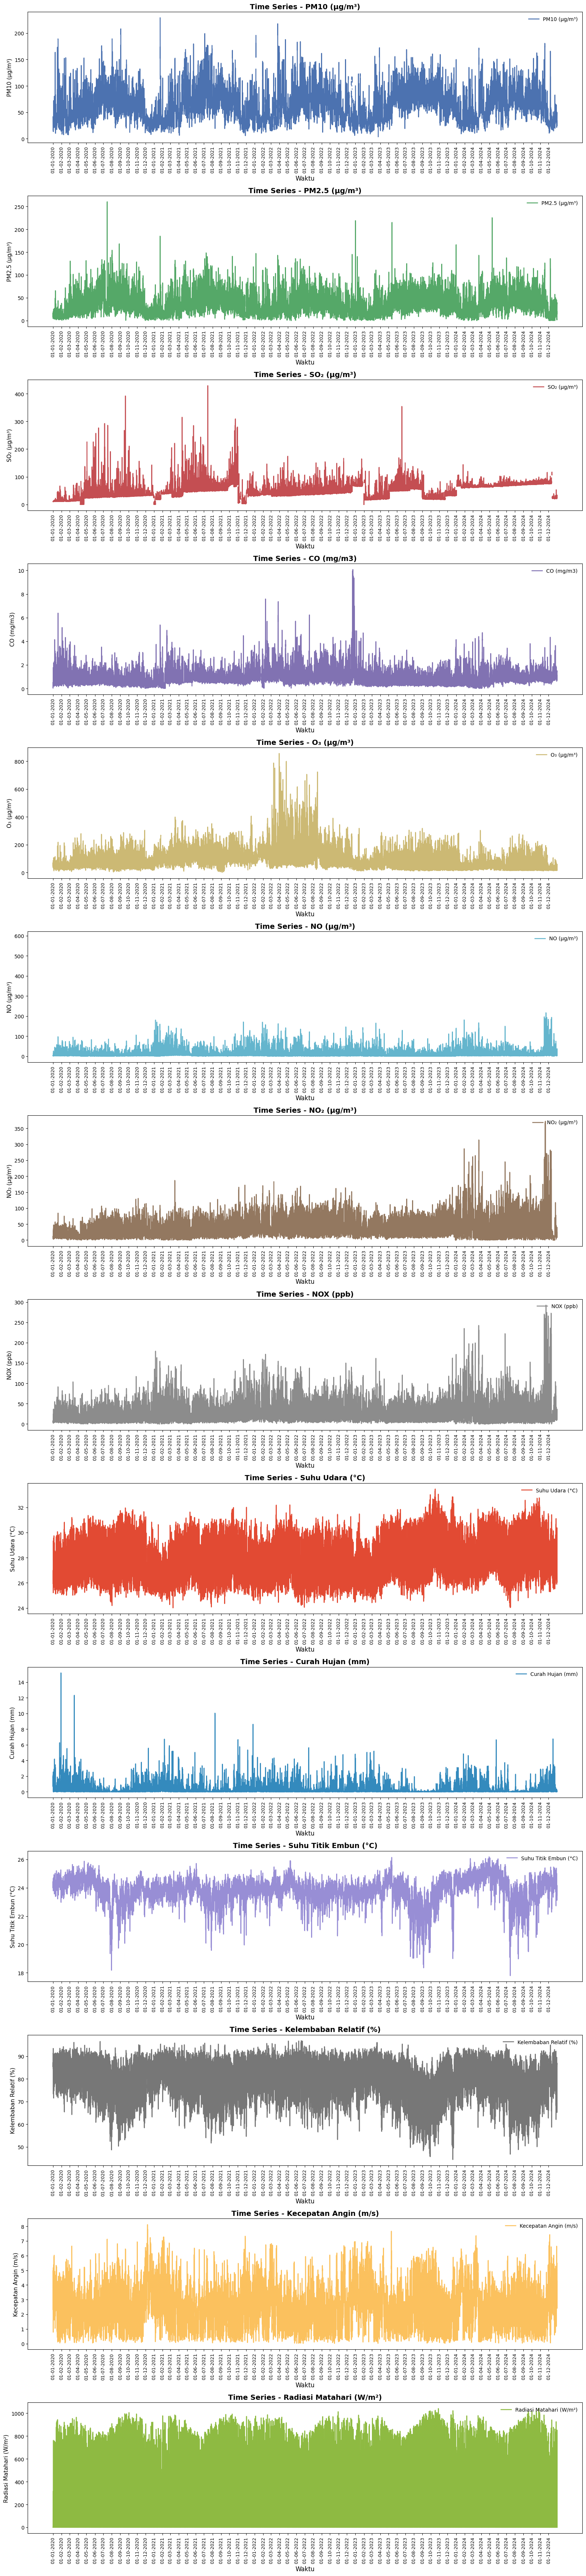

In [7]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)

df_ts = df_ts.sort_index()
hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)
xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]


xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()


In [8]:
df['datetime'] = pd.to_datetime(df['datetime'])
datetime_index = df['datetime']
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric = df[numeric_cols]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)





In [9]:
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

In [10]:
df_imputed_numeric = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns=numeric_cols
)

In [11]:
df_imputed = df_imputed_numeric.copy()
df_imputed.index = datetime_index
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
datetime,,,,,,,,,,,,,,
2020-01-01 00:00:00,41.36,15.24,10.79,0.49,65.69,2.27,11.92,7.49,25.940001,1.93,24.400000,91.239998,2.326,0.000000
2020-01-01 01:00:00,40.13,16.33,10.43,0.32,59.90,2.11,7.95,5.45,26.090000,1.42,24.370001,90.269997,3.223,0.000000
2020-01-01 02:00:00,38.24,7.32,10.25,0.24,58.21,1.21,5.28,3.47,26.590000,0.83,23.980000,85.620003,4.329,0.000000
2020-01-01 03:00:00,36.24,7.69,11.00,0.26,65.44,1.17,4.28,2.96,26.830000,0.67,24.150000,85.279999,4.737,0.000000
2020-01-01 04:00:00,32.48,7.60,10.83,0.25,71.62,4.51,9.43,7.96,26.709999,0.94,24.340000,86.870003,4.895,0.000000
2020-01-01 05:00:00,29.38,17.54,10.97,0.03,57.06,1.23,5.90,3.79,27.000000,1.63,24.379999,85.610001,4.988,0.000000
2020-01-01 06:00:00,22.84,6.68,10.22,0.25,35.10,1.34,8.03,4.91,26.940001,2.16,24.389999,85.959999,4.150,25.500000
2020-01-01 07:00:00,18.48,5.09,10.25,0.36,60.06,1.98,10.14,6.41,26.770000,1.12,24.480000,87.290001,3.557,88.370003
2020-01-01 08:00:00,18.00,5.47,10.18,0.28,52.22,1.38,7.00,4.44,26.950001,1.47,24.309999,85.500000,3.233,152.309998


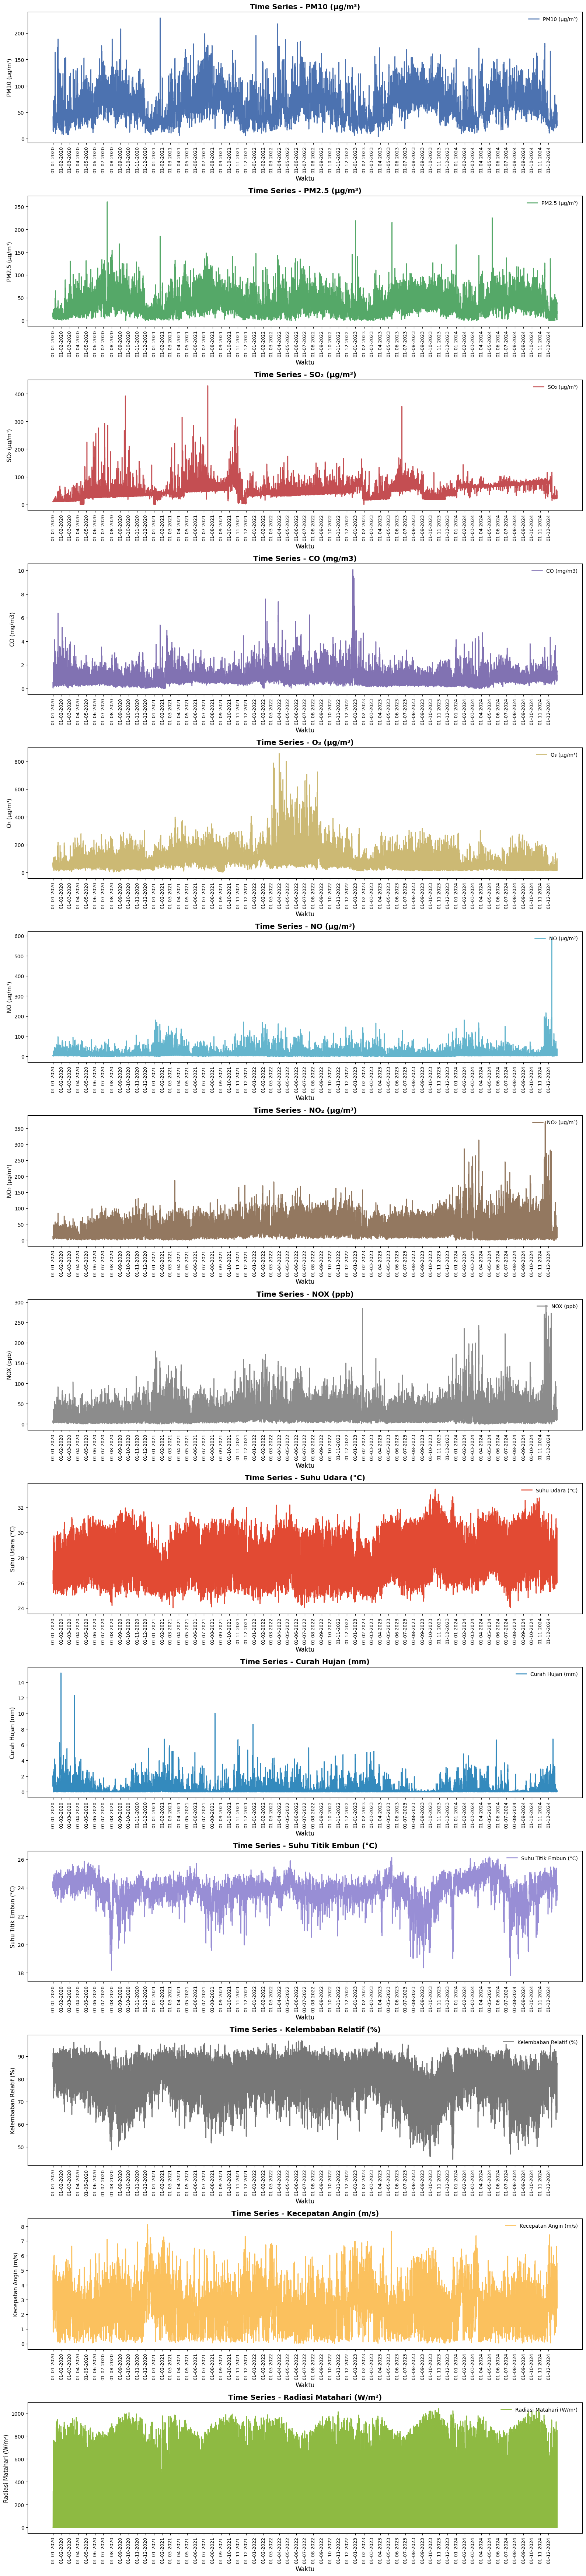

In [12]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)

df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(),
                       freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()





In [13]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,64.62,35.01,46.91,0.92,91.87,10.22,36.24,25.15,27.68,0.23,23.81,80.04,2.44,224.90
std,29.39,21.07,23.44,0.65,68.38,15.76,27.69,22.15,1.66,0.53,0.86,8.67,1.29,299.51
min,3.61,0.01,0.03,0.01,1.34,0.01,0.02,0.01,24.01,0.00,17.80,44.46,0.01,0.00
25%,41.00,18.91,31.01,0.51,43.97,1.91,15.64,9.67,26.30,0.00,23.42,74.27,1.46,0.00
50%,62.12,31.94,43.23,0.76,76.73,4.42,29.29,18.70,27.43,0.04,23.90,81.65,2.21,13.06
75%,83.26,47.21,63.96,1.16,121.13,11.52,50.99,34.10,28.92,0.20,24.35,87.30,3.25,451.58
max,229.00,260.29,428.89,10.07,855.53,592.32,372.29,292.40,33.46,15.18,26.18,96.81,8.11,1040.83


In [14]:
df_imputed.loc[:, ~df_imputed.columns.isin(['NO', 'NOX'])].describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,64.62,35.01,46.91,0.92,91.87,36.24,27.68,0.23,23.81,80.04,2.44,224.90
std,29.39,21.07,23.44,0.65,68.38,27.69,1.66,0.53,0.86,8.67,1.29,299.51
min,3.61,0.01,0.03,0.01,1.34,0.02,24.01,0.00,17.80,44.46,0.01,0.00
25%,41.00,18.91,31.01,0.51,43.97,15.64,26.30,0.00,23.42,74.27,1.46,0.00
50%,62.12,31.94,43.23,0.76,76.73,29.29,27.43,0.04,23.90,81.65,2.21,13.06
75%,83.26,47.21,63.96,1.16,121.13,50.99,28.92,0.20,24.35,87.30,3.25,451.58
max,229.00,260.29,428.89,10.07,855.53,372.29,33.46,15.18,26.18,96.81,8.11,1040.83


In [ ]:
df_imputed['datetime'] = df_imputed.index
df_imputed.to_excel("/content/drive/MyDrive/Model/Data Imputasi/df_imputed 2.xlsx", index=False)